# LedgerX — measured performance

This notebook **reads existing measurements**. It does not start a benchmark, connect to
PostgreSQL or move money. Use `bash scripts/verify_local.sh --benchmark-only` to collect data.

Measurement pipeline: real HTTP / PostgreSQL → raw JSON → validated analysis → figures.
The saved outputs were executed sequentially by `analysis.render_report` in a Python process,
without a Jupyter server. In Jupyter, **Restart Kernel and Run All** reproduces the analysis.
Use a kernel containing Matplotlib; the existing Anaconda environment has it.


In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd().resolve()
if root.name == "analysis":
    root = root.parent
assert (root / "artifacts/benchmark.json").exists(), "Open from LedgerX or LedgerX/analysis"
os.environ["MPLCONFIGDIR"] = str(root / ".runtime/matplotlib")
os.environ["XDG_CACHE_HOME"] = str(root / ".runtime/cache")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt  # noqa: E402

from analysis.performance import (  # noqa: E402
    concurrency_figure,
    distribution_figure,
    load_reports,
    profiling_figure,
)

benchmark, profiling = load_reports()
print("Measured:", benchmark["started_at"])
print("Server:", benchmark["server"])
print("Generator:", benchmark["environment"])
print("Source SHA-256:", benchmark["source_sha256"])
print("Cases:", len(benchmark["runs"]))
print("Timed requests:", sum(run["requests"] for run in benchmark["runs"]))
print("Unexpected responses:", sum(run["unexpected_responses"] for run in benchmark["runs"]))
print(
    "All accounting checks passed:",
    all(run["reconciliation"]["consistent"] for run in benchmark["runs"]),
)

Measured: 2026-10-20T19:26:00.751332+00:00
Server: {'status': 'ok', 'version': '0.3.0', 'schema': '0003', 'postgresql': '16.15'}
Generator: {'platform': 'macOS-15.6-arm64-arm-64bit', 'python': '3.12.12', 'logical_cpus': 10}
Source SHA-256: fa464ac0c5212908af39e90f58d7f72be7fe2c879fc5d9e64832602232d5c3ae
Cases: 90
Timed requests: 18000
Unexpected responses: 0
All accounting checks passed: True


## Concurrency and contention

Each point is the median of three repetitions; whiskers show their observed min/max,
**not confidence intervals**. Each repetition contains 200 timed requests after warmup.
Read requests, new transfers and refunds remain separate series.

Compare eight clients with 32 and shared accounts with independent transfers. More
concurrency can increase queueing and lock contention. These curves alone do not
isolate every source of delay; inspect both throughput and the latency tail.


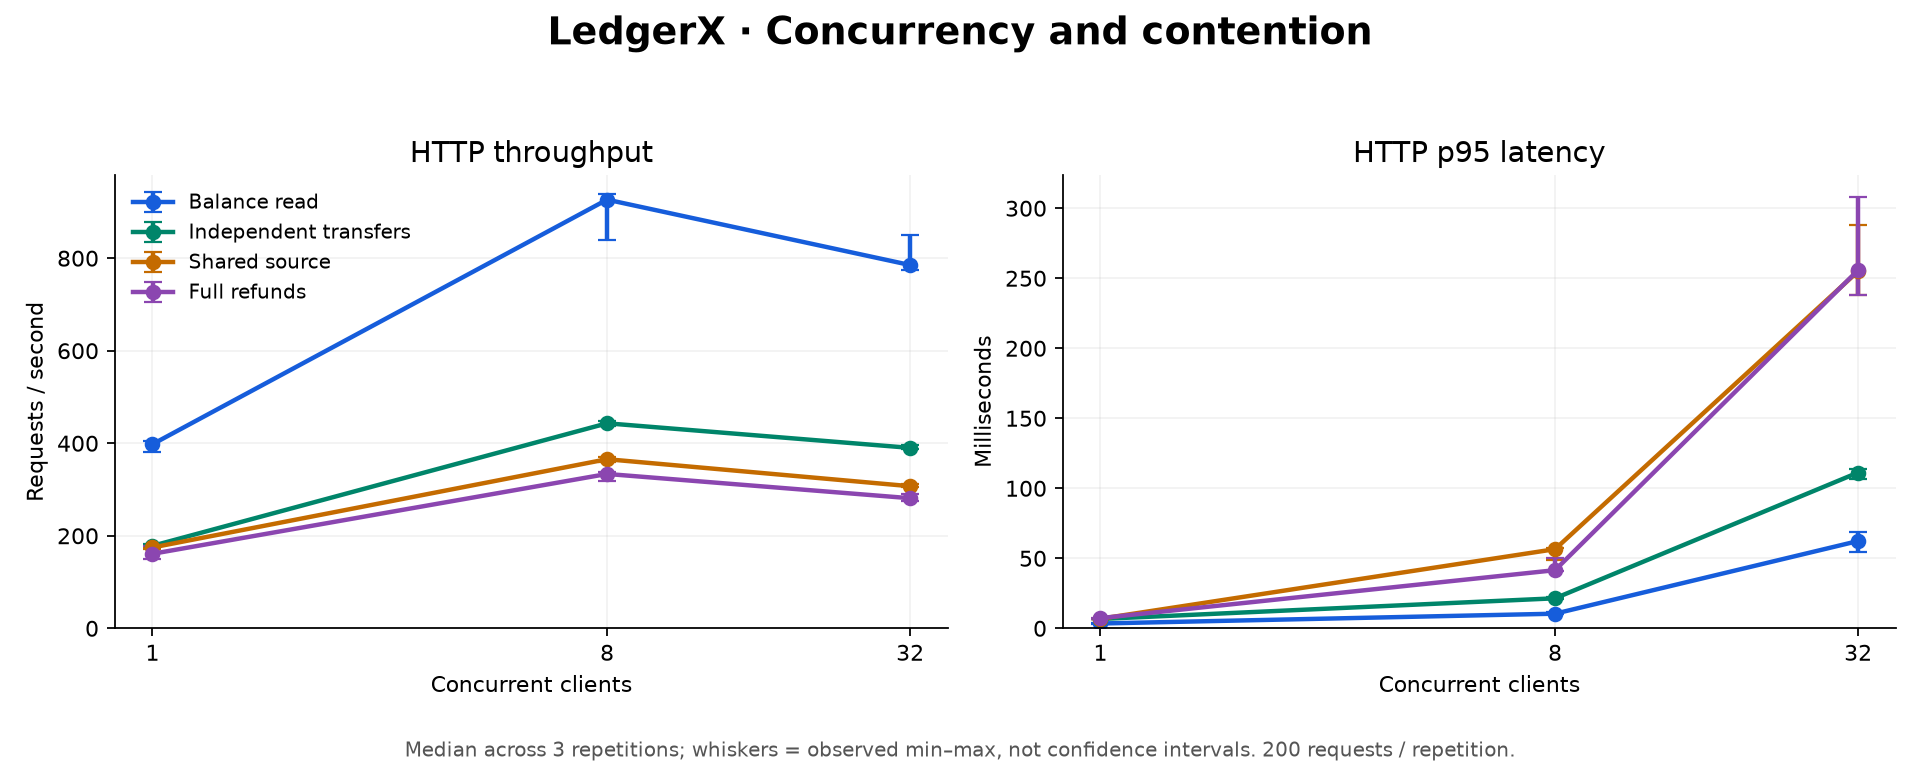

In [2]:
fig = concurrency_figure(benchmark)
display(fig)
plt.close(fig)

## Full latency distributions

Every recorded response is retained, including the slowest. Curves combine the three
repetitions only to display their raw observations; they are not independent capacity trials.
A log-scaled x-axis makes both ordinary and tail responses visible.


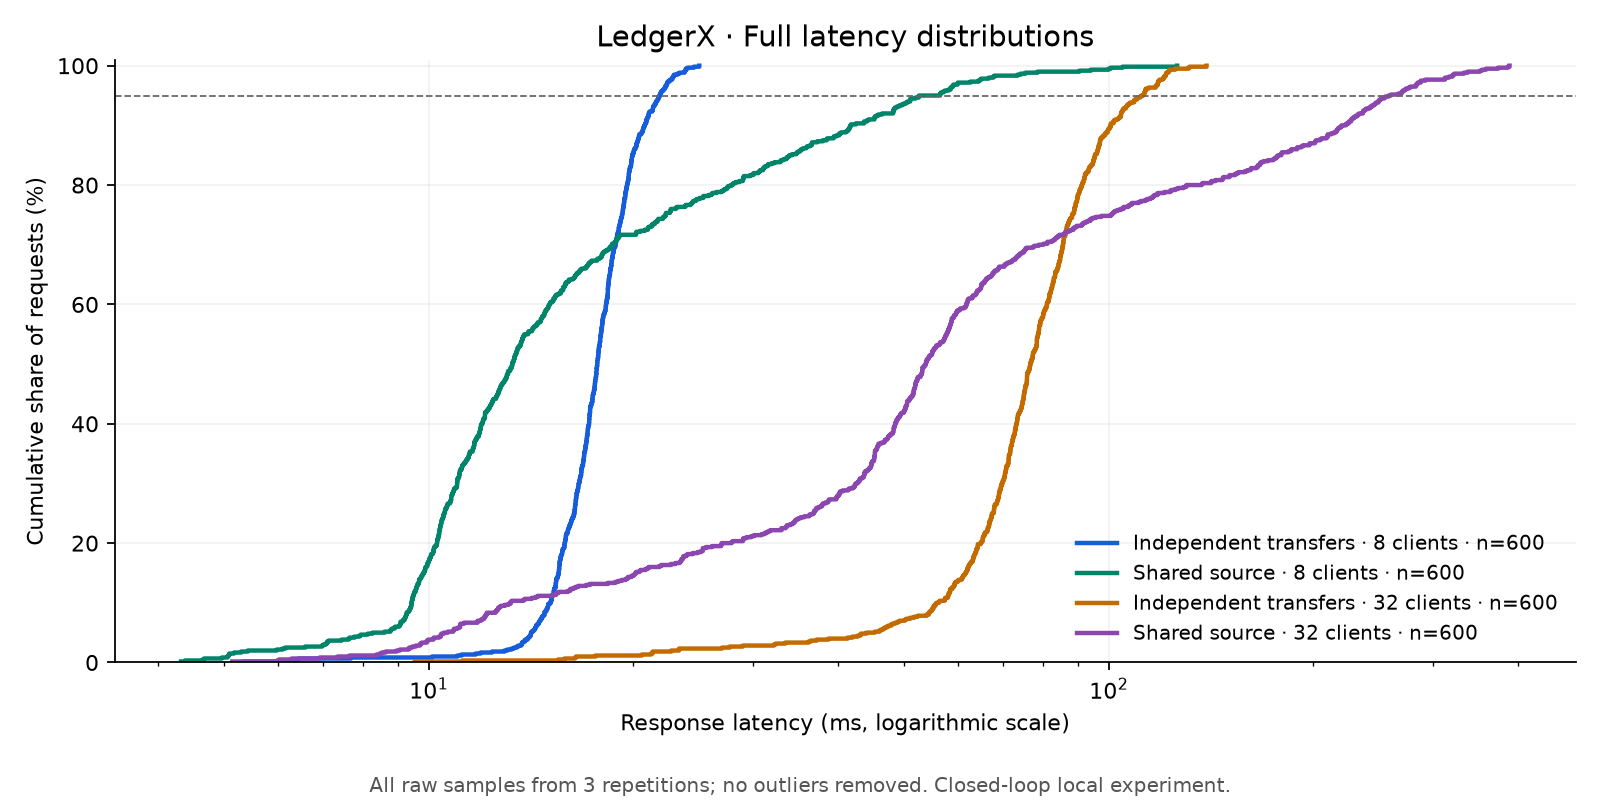

In [3]:
fig = distribution_figure(benchmark)
display(fig)
plt.close(fig)

## Service and SQL profiling

Service times include the database commit and cProfile overhead, with 100 transfers per
initial history depth. SQLAlchemy cursor timings exclude commit, where deferred triggers run.
The plan timings are single `EXPLAIN (ANALYZE, BUFFERS)` observations after the service workload.

The first baseline was non-monotonic across history depths. Do not fit a scalability law
or attribute timing differences solely to trigger cost. A faster cursor SQL observation
does not establish an equivalent end-to-end HTTP improvement.


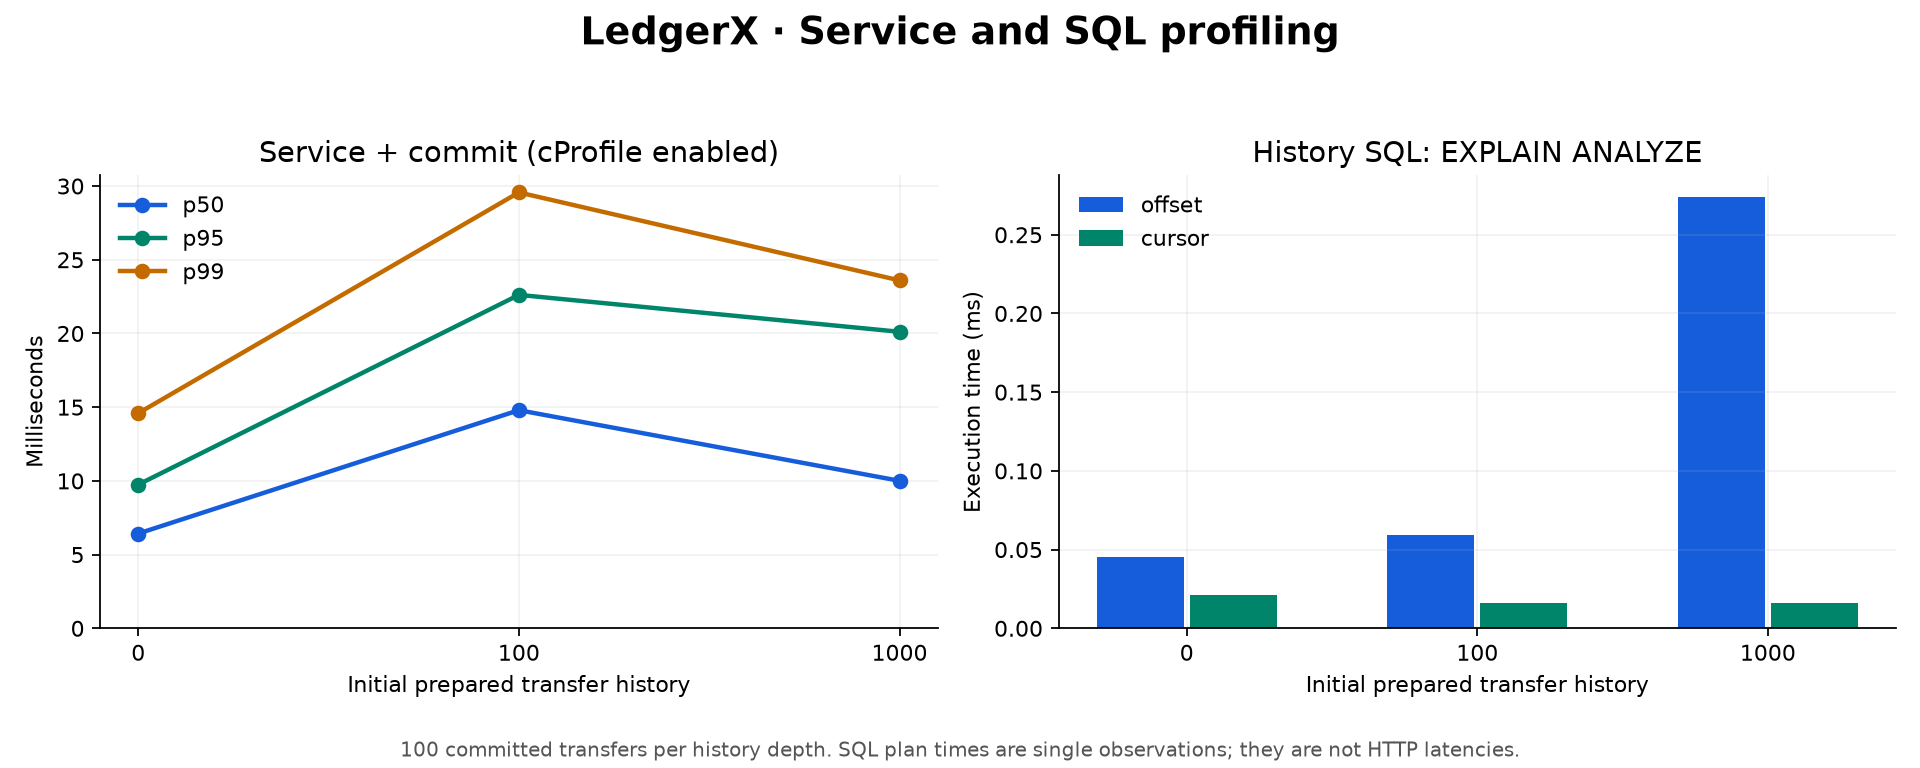

Depth 0 SQL cursor calls: 700 peak process RSS: 77316096 bytes
Depth 100 SQL cursor calls: 700 peak process RSS: 78102528 bytes
Depth 1000 SQL cursor calls: 700 peak process RSS: 78168064 bytes
PostgreSQL settings: {'fsync': 'on', 'lock_timeout': '2000', 'max_connections': '100', 'shared_buffers': '16384', 'statement_timeout': '10000', 'synchronous_commit': 'on'}


In [4]:
fig = profiling_figure(profiling)
display(fig)
plt.close(fig)
for run in profiling["runs"]:
    print(
        "Depth",
        run["prepared_transfer_history"],
        "SQL cursor calls:",
        sum(row["calls"] for row in run["sql_execute_excluding_commit"]),
        "peak process RSS:",
        run["process_peak_rss_bytes_including_setup"],
        "bytes",
    )
print("PostgreSQL settings:", profiling["database_settings"])

## Before/after: one fewer SQL operation for a new key

The original run is retained in `artifacts/baseline`. The optimization uses
`INSERT ... ON CONFLICT DO NOTHING RETURNING ...` to obtain a new reservation directly.
Existing keys still use a locked SELECT, preserving replay/conflict coordination.

Compare **cursor operations per committed service transfer** separately from wall-clock
performance. Host load and total database history changed between sequential runs;
HTTP differences are observations, not a controlled causal percentage improvement.


In [5]:
import json
from statistics import median

baseline_path = root / "artifacts/baseline"
if (baseline_path / "profiling.json").exists() and json.loads(
    (baseline_path / "benchmark.json").read_text()
)["source_sha256"] != benchmark["source_sha256"]:
    baseline_profile = json.loads((baseline_path / "profiling.json").read_text())
    baseline_http = json.loads((baseline_path / "benchmark.json").read_text())
    print("Before source:", baseline_http["source_sha256"])
    print("After source: ", benchmark["source_sha256"])
    before_by_depth = {run["prepared_transfer_history"]: run for run in baseline_profile["runs"]}
    for current in profiling["runs"]:
        previous = before_by_depth[current["prepared_transfer_history"]]
        before = sum(row["calls"] for row in previous["sql_execute_excluding_commit"])
        after = sum(row["calls"] for row in current["sql_execute_excluding_commit"])
        print(
            "Depth",
            current["prepared_transfer_history"],
            "cursor calls/transfer:",
            before / previous["samples"],
            "->",
            after / current["samples"],
        )
    for scenario in ("independent_transfers", "shared_source", "reversals"):
        rates = [
            median(
                run["requests_per_second"]
                for run in report["runs"]
                if run["scenario"] == scenario and run["concurrency"] == 8
            )
            for report in (baseline_http, benchmark)
        ]
        print(
            scenario,
            "8 clients, observed median req/s:",
            round(rates[0], 1),
            "->",
            round(rates[1], 1),
        )
else:
    print("No distinct measured revision is available; no before/after gain is claimed.")

No distinct measured revision is available; no before/after gain is claimed.


## What this proves — and its limits

- All measured cases returned expected statuses and passed exact balance/reconciliation checks.
- Expected 409 refusals and idempotent replays are not new payments.
- The generator is closed-loop: it slows when responses slow (coordinated omission).
- Three repetitions and 200 samples per case are limited evidence for p99 or capacity planning.
- The database grows across scenarios; runs are sequential, not randomized controlled trials.
- macOS, Docker VM allocation, background load and profiler overhead affect the observations.
- This archived baseline has no open-loop load test. The separate 22 October experiment follows.
- There is no production SLO or long-duration soak-test claim.

The function-level reports are `artifacts/profile-depth-*.txt`; binary cProfile files are local
artifacts. Raw HTTP samples and SQL plans remain in JSON. See `docs/ENGINEERING_REPORT.md` for
test evidence and architectural trade-offs.

Notebook approach: [Jupyter documentation](https://docs.jupyter.org/en/latest/).
Profiling reference: [Python 3.12 profilers](https://docs.python.org/3.12/library/profile.html).


## Schema 0004: recorded incremental-projection experiment

The separate 22 October reports are in `artifacts/latency/`. These figures include all three
repetitions, commit timings and fixed-arrival drops. The generator shares the Mac with the server;
high-load failures cannot be attributed to the server alone. Dropped arrivals were never sent.
The 20 October baseline above remains historical, not a controlled causal comparison.


In [6]:
from analysis.render_latency import render  # noqa: E402

latency_dir = root / "artifacts/latency"
load = json.loads((latency_dir / "open-loop.json").read_text())
profile = json.loads((latency_dir / "profiling.json").read_text())
assert load["source_sha256"] == profile["source_sha256"]
render(latency_dir)
print("Source SHA-256:", load["source_sha256"])
for field in (
    "offered_requests",
    "sent_requests",
    "dropped_arrivals",
    "unexpected_responses",
    "unconfirmed_outcomes",
):
    print(field, sum(run[field] for run in load["runs"]))
print("Accounting verified:", load["accounting_verified"])
print("All load targets met:", load["all_targets_met"])
for depth in sorted({run["prepared_transfer_history"] for run in profile["runs"]}):
    runs = [run for run in profile["runs"] if run["prepared_transfer_history"] == depth]
    print(
        "Depth",
        depth,
        "median service p95 ms:",
        round(median(run["service_including_commit_ms"]["p95"] for run in runs), 3),
        "median commit p95 ms:",
        round(median(run["commit_ms"]["p95"] for run in runs), 3),
    )

Source SHA-256: e4b2ef44e64cfc2b740f92f0273f25d6fc15398d21688b583ba16593350c2b08
offered_requests 30000
sent_requests 18439
dropped_arrivals 11561
unexpected_responses 0
unconfirmed_outcomes 0
Accounting verified: True
All load targets met: False
Depth 0 median service p95 ms: 4.85 median commit p95 ms: 0.717
Depth 100 median service p95 ms: 4.638 median commit p95 ms: 0.606
Depth 1000 median service p95 ms: 4.748 median commit p95 ms: 0.601
Depth 10000 median service p95 ms: 5.75 median commit p95 ms: 0.622


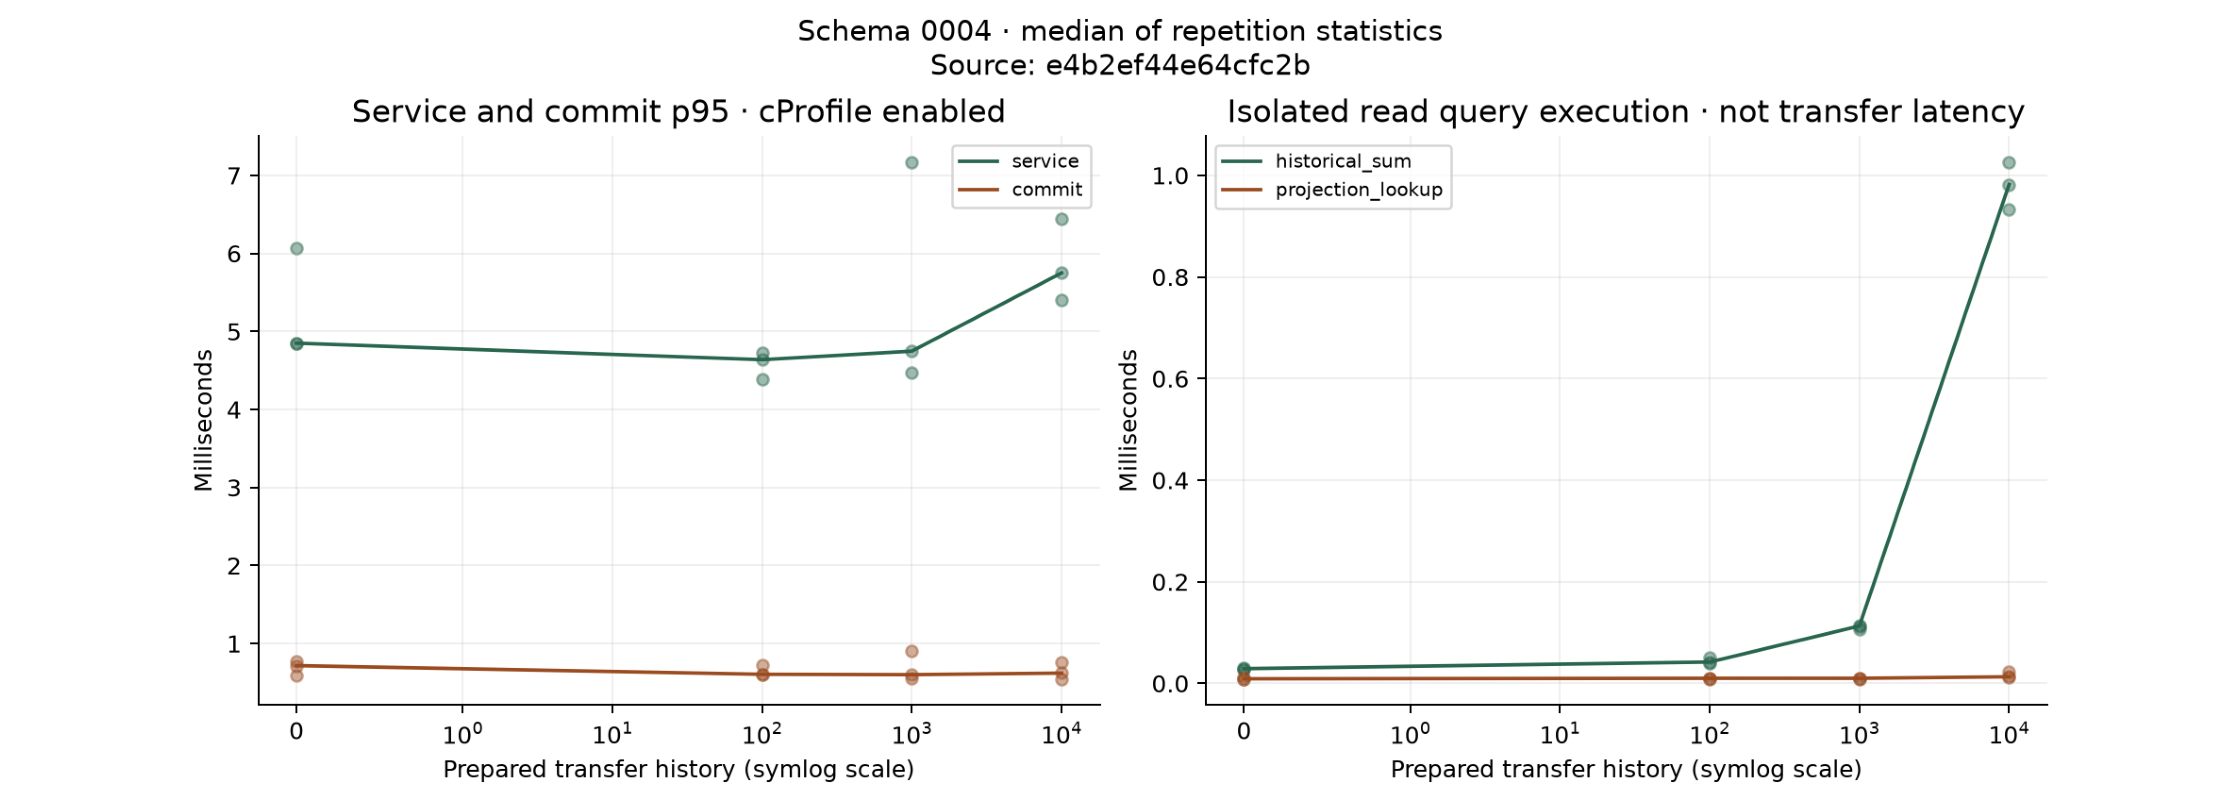

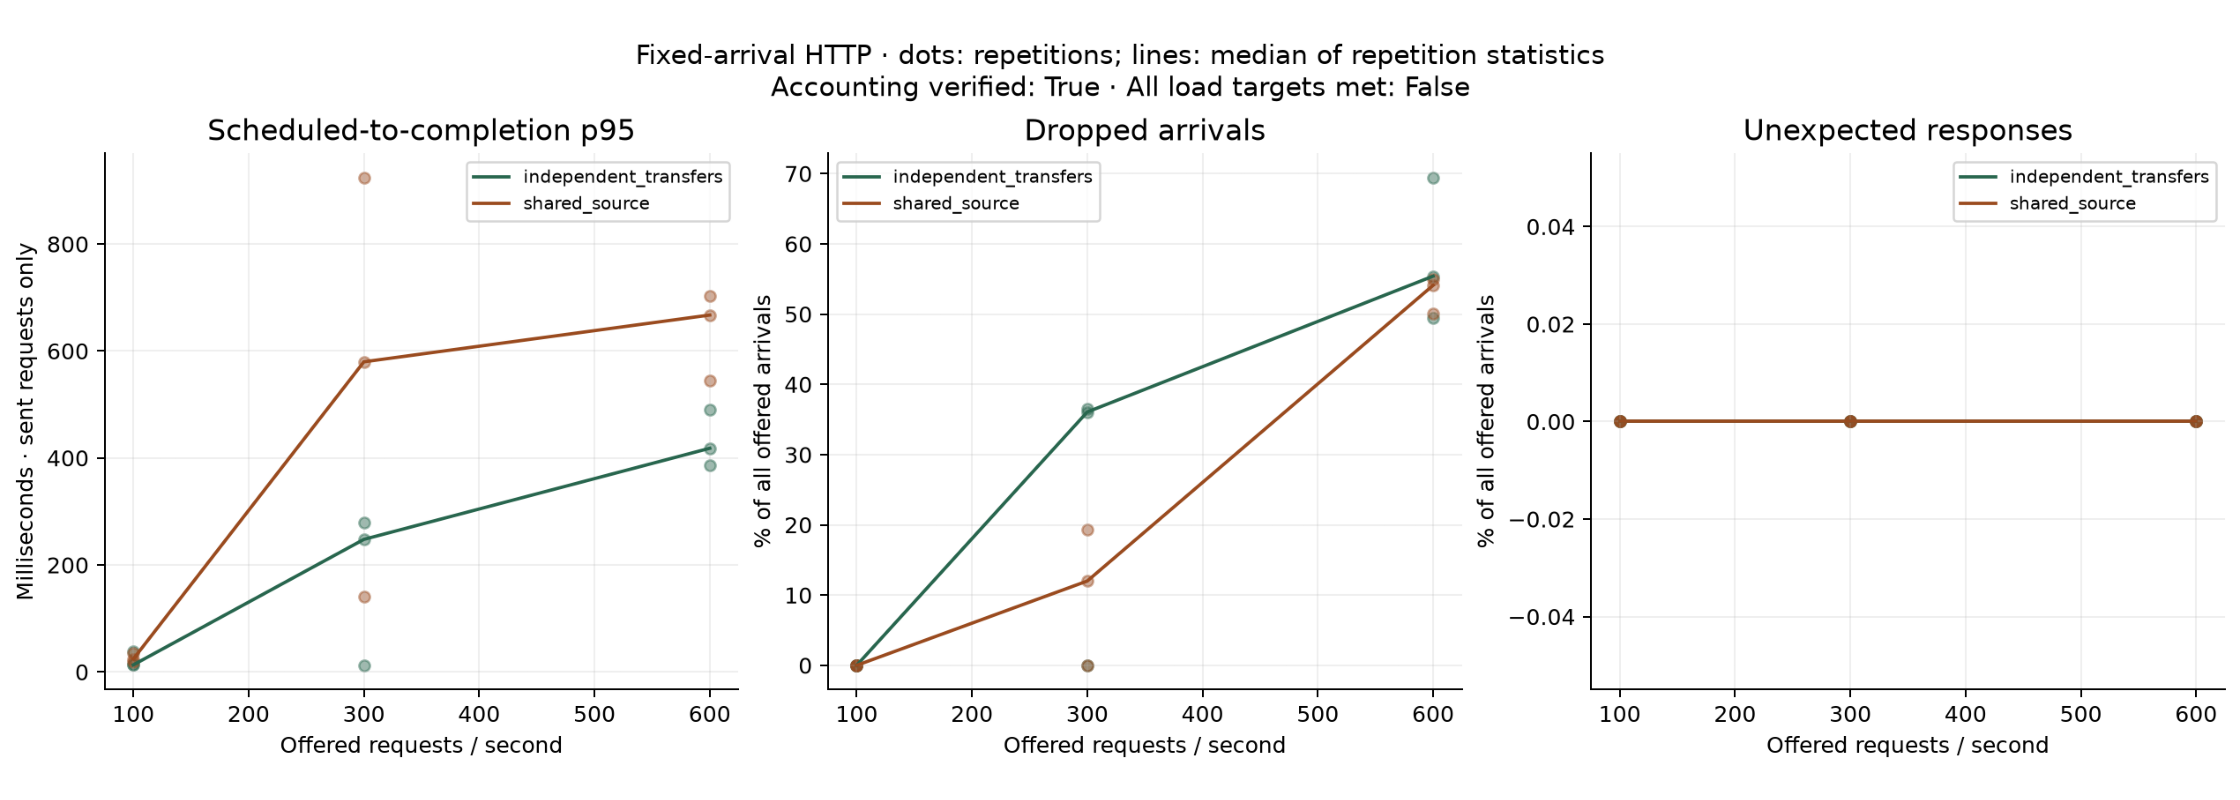

In [7]:
for name in ("history-and-commit", "fixed-arrival-load"):
    pixels = plt.imread(latency_dir / "figures" / f"{name}.png")
    fig, axis = plt.subplots(figsize=(14, 5))
    axis.imshow(pixels)
    axis.set_axis_off()
    fig.tight_layout(pad=0)
    display(fig)
    plt.close(fig)

All six short 100 requests/s cases met their load target.
Only two of six did at
300 requests/s; none did at 600. Zero unexpected responses does not mean every arrival was served:
11,561 of 30,000 were dropped. The p95 values cover sent requests and must accompany
the drop counts.
See `docs/LATENCY_RESULTS.md` for the tables, storage snapshot and verification boundaries.
